# **Final Year Project - Year 4 Software Development**
## Chord Prompt Notebook - Testing Area

*By Mark Lambert - C00192497*

*21/10/2026*

---

The following notebook was developed during the first iteration as a target release goal. It now serves as the main hub to test the code developed in `chord_detect.py`. 

The user is prompted with three images of chords represented as chord diagrams. Once prompted, recording is initiated, the user strums the chords and analysis is performed with the functions defined `chord_detect.py`

In [1]:
# Source - https://stackoverflow.com/a/26392492
# Posted by user1269942
# Retrieved 2026-10-21, License - CC BY-SA 3.0

from PIL import Image
from pathlib import Path
import glob
# chord dict, so name can be tracked and matched with template
chords = {}
for filename in glob.glob('../data/chords/*.jpg'):
    # need pathlib to get the filename, for analysis use -> matching against tempalte
    name = Path(filename).stem
    chords[name] = Image.open(filename)
import random
prompt_chords = random.sample(list(chords), 3)
prompt_chords = ["F", "Dm", "E"]

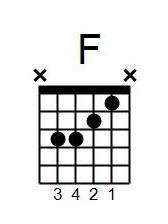

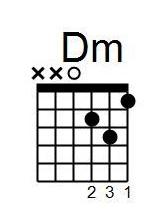

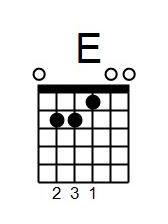

Chord: F, Score:57.00%
Chord: D, Score:79.48%
Chord: E, Score:70.89%
Transition time: 00.87 seconds
Transition time: 00.75 seconds


In [2]:
from IPython.display import display
import sys
sys.path.insert(0, "../fretwave")
from chord_detect import record, get_chords, check_chords
import librosa

for name in prompt_chords:
    display(chords[name])
# clip, sr = record()
clip, sr = librosa.load("../data/clips/F-Dm-E.wav", sr=None)
detected, times = get_chords(clip, sr)
for t in times:
    mins, secs = divmod(t, 60)
    print(f"Transition time: {secs:05.2f} seconds")

Now with the transition times computed with a consistent, reliable onset detection algorithm, I can begin the work on implementing transition times in the `skill_levels` module for analysis

In [3]:
print("----Resultss----")
results = check_chords(detected, prompt_chords)
print(results)
print("----Skill Feedback----")
from skill_levels import skill_levels, chord_accepted
levels = ["beginner", "intermediate", "advanced"]
for chord, score in detected: 
    chord_accepted(levels[0], chord, score)

----Resultss----
[('F', True), ('Dm', False), ('E', True)]
----Skill Feedback----
Chord accuracy 57.00 is below the threshold for beginner guitar players (60)
Chord D detected!
Chord E detected!


## Sources

- user1269942 (2014) Importing images from a directory (Python) to list or dictionary, Stack Overflow [Online forum] Available at: https://stackoverflow.com/a/26392492 [Accessed: 